# Training: superpixels, GMM and manual-label preparation
Run cells in order using **Python (crystal_seg)**, from this folder or the project root. All drawing code is inside this notebook. Only one image is processed. After the original-resolution crop comparison, analysis uses a preview with maximum side 640 pixels (`MAX_SIDE`); preview results differ from full-resolution production results. Tutorial results go to a separate `tutorial_001` folder. Main-run outputs and models are read without modification.

The GMM demonstration standardizes the real image features, reduces them to **two PCA axes**, and fits a **full-covariance 2D GMM** so that its Gaussian ellipses can be drawn directly. This is an educational model, not the production segmentation or RF pipeline. Production implementation normally uses up to 15 PCs; training uses its configured PCs; coverage fits diagonal GMMs on all six standardized features, without PCA. Cluster numbers do not identify crystal categories.

## 1. Paths and one input image

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from skimage import io
import joblib
from IPython.display import display

WORK_DIR = Path.cwd().resolve()
if not (WORK_DIR / "training_tutorial.ipynb").is_file(): WORK_DIR /= "training"
if not (WORK_DIR / "training_tutorial.ipynb").is_file(): raise FileNotFoundError("Start from training/ or the project root.")
PROJECT_ROOT = WORK_DIR.parent
sys.path.insert(0, str(PROJECT_ROOT / "implement"))
sys.path.insert(0, str(WORK_DIR))
IMAGE_PATH = sorted((PROJECT_ROOT / "data/mag500/training").glob("*.jpg"))[0]
OUTPUT_DIR = WORK_DIR / "output" / "tutorial_archived_features_001"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Image: {IMAGE_PATH}\nTutorial outputs: {OUTPUT_DIR}")

REFERENCE_PATH = PROJECT_ROOT / "implement" / "data" / "models" / "rf_step1.pkl"

Image: /home/kmanabe2403/dune/data/mag500/training/0000_20260807_095058.jpg
Tutorial outputs: /home/kmanabe2403/dune/training/output/tutorial_archived_features_001


## 2. Crop
The red rectangle marks the retained area. The same crop margins are used in the main notebooks.

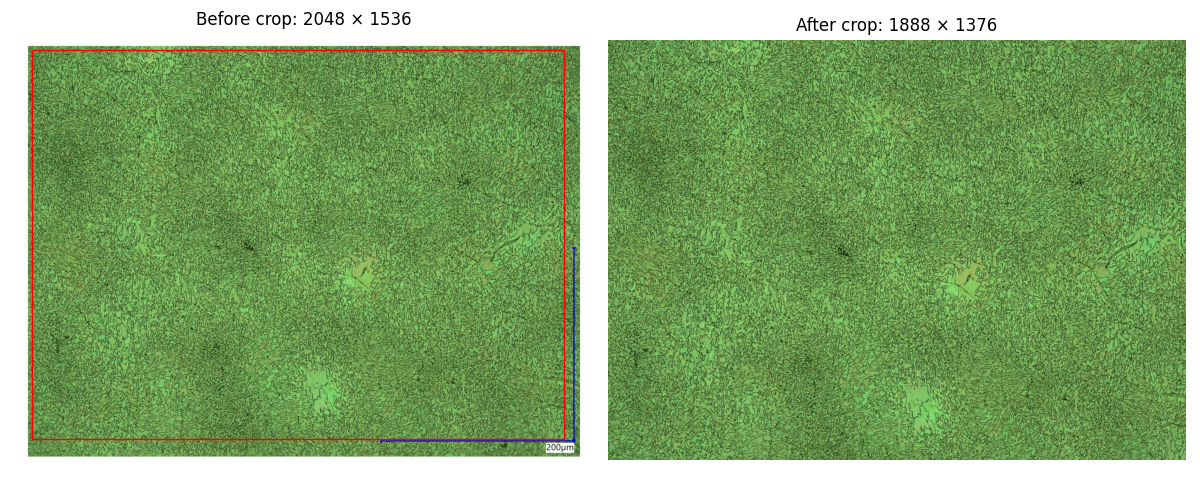

Analysis preview: (466, 640, 3); main-pipeline images are unchanged.


In [2]:
original = io.imread(IMAGE_PATH)
h, w = original.shape[:2]
crop = {"top": 60, "bottom": 100, "left": 60, "right": 100}
image = original[crop["top"]:h-crop["bottom"], crop["left"]:w-crop["right"]].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(original)
axes[0].add_patch(Rectangle((crop["left"], crop["top"]), image.shape[1], image.shape[0], fill=False, edgecolor="red", linewidth=1))
axes[0].set_title(f"Before crop: {original.shape[1]} × {original.shape[0]}")
axes[1].imshow(image)
axes[1].set_title(f"After crop: {image.shape[1]} × {image.shape[0]}")
for ax in axes: ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_crop.png", dpi=120)
plt.show()
plt.close(fig)
del original

from skimage.transform import resize
MAX_SIDE = 640  # Use None for full-resolution analysis (slower and more memory-intensive).
if MAX_SIDE is not None and max(image.shape[:2]) > MAX_SIDE:
    shape = tuple(max(1, round(v * MAX_SIDE / max(image.shape[:2]))) for v in image.shape[:2])
    image = resize(image, shape, preserve_range=True, anti_aliasing=True).round().astype(np.uint8)
print(f'Analysis preview: {image.shape}; main-pipeline images are unchanged.')

## 3. Superpixels
Each superpixel groups nearby pixels. Thin red lines show their boundaries. This calls the same SLIC preprocessing as the main pipeline, including its original color handling.

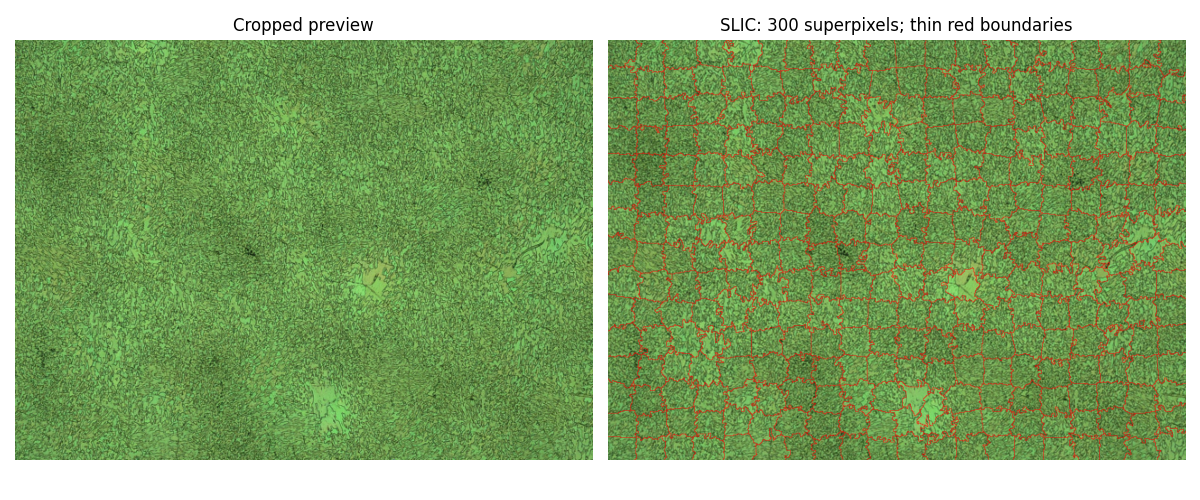

In [3]:
from skimage.color import rgb2lab
from skimage.segmentation import slic, mark_boundaries

# Same SLIC call/color handling as production, applied to the smaller tutorial preview.
lab = rgb2lab(image)
segments = slic(lab, n_segments=300, compactness=10.0, sigma=1, start_label=1)
sp_labels = np.unique(segments)
means = np.array([lab[segments == label].mean(axis=0) for label in sp_labels], dtype=np.float32)
PREPROCESS_DIR = OUTPUT_DIR / "preprocessing"
PREPROCESS_DIR.mkdir(parents=True, exist_ok=True)
np.save(PREPROCESS_DIR / "image.npy", image)
np.save(PREPROCESS_DIR / "segments.npy", segments)
np.savez(PREPROCESS_DIR / "lab_means.npz", labels=sp_labels, lab_means=means)
del lab
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image)
axes[0].set_title("Cropped preview")
axes[1].imshow(np.clip(mark_boundaries(image, segments, color=(1, 0, 0), mode="subpixel"), 0, 1))
axes[1].set_title(f"SLIC: {len(sp_labels)} superpixels; thin red boundaries")
for ax in axes: ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_superpixels.png", dpi=120)
plt.show()
plt.close(fig)

## 4. Real features
Use the same 18 superpixel features and fixed Lab reference as the main pipeline. No reference is learned from this tutorial image.

In [4]:
from crystal_features import calculate_image_features, FEATURE_NAMES

with np.load(PREPROCESS_DIR / "lab_means.npz") as saved:
    sp_labels, means = saved["labels"], saved["lab_means"]
reference = np.asarray(joblib.load(REFERENCE_PATH)["reference_mean"])
preview_lab = rgb2lab(image)
means = np.array([preview_lab[segments == label].mean(axis=0) for label in sp_labels])
del preview_lab
correction = reference - means.mean(axis=0)
corrected_path = OUTPUT_DIR / "corrected_lab.npz"
np.savez(corrected_path, labels=sp_labels, lab_means=means + correction, correction=correction)
sp_labels, features = calculate_image_features(PREPROCESS_DIR, corrected_path)
feature_names = FEATURE_NAMES
np.savez(OUTPUT_DIR / "features.npz", labels=sp_labels, features=features, feature_names=feature_names)
print(f"{len(features)} superpixels × {features.shape[1]} features; same feature functions as the main pipeline.")

300 superpixels × 18 features; same feature functions as the main pipeline.


## PCA: two axes for the demonstration
PCA axes are weighted combinations of standardized features. Their signs are arbitrary. The printed variance fraction indicates how much variation survives the 2D reduction.

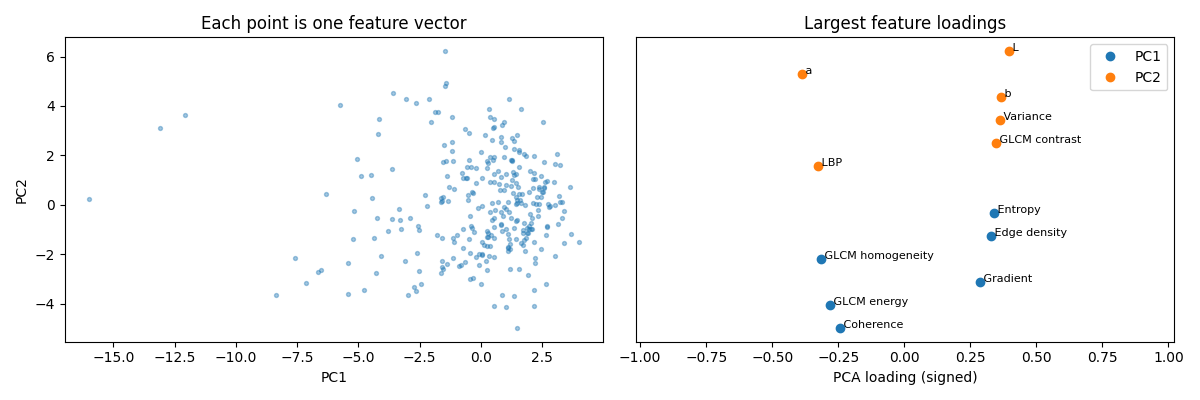

PCA variance retained: 60.8%


In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
pca = PCA(n_components=2, random_state=0)
X = pca.fit_transform(scaler.fit_transform(features))
print(f"PCA variance retained: {pca.explained_variance_ratio_.sum():.1%}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(X[:, 0], X[:, 1], s=8, alpha=.4)
axes[0].set(xlabel="PC1", ylabel="PC2", title="Each point is one feature vector")
for pc in range(2):
    order = np.argsort(np.abs(pca.components_[pc]))[-6:]
    axes[1].plot(pca.components_[pc, order], np.arange(len(order)) + pc * 7, "o", label=f"PC{pc+1}")
    for j, idx in enumerate(order): axes[1].text(pca.components_[pc, idx], j + pc * 7, " " + feature_names[idx], fontsize=8)
axes[1].set(xlabel="PCA loading (signed)", yticks=[], title="Largest feature loadings")
axes[1].margins(x=.8)
axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_pca.png", dpi=120)
plt.show()
plt.close(fig)

## EM: initialization → 5 updates → convergence
The same initialized model continues through all snapshots. Step 0 has initial parameters but no EM updates; its colors are the initial posterior assignments. Each EM update calculates soft responsibilities (E step), then updates means, covariances and mixture weights (M step). Fixed initialization makes reruns reproducible. If 500 updates are insufficient, the final plot explicitly reports the iteration limit.

In [6]:
from copy import deepcopy
import warnings
from sklearn.mixture import GaussianMixture
from sklearn.exceptions import ConvergenceWarning

N_CLUSTERS = 3  # Try 2 or 4 after completing the tutorial.
# Initialize once, then continue the SAME model one EM update at a time.
initial_means = X[np.random.default_rng(0).choice(len(X), N_CLUSTERS, replace=False)]
gmm = GaussianMixture(N_CLUSTERS, covariance_type="full", random_state=0, n_init=1, init_params="random",
                      means_init=initial_means, weights_init=np.full(N_CLUSTERS, 1 / N_CLUSTERS),
                      reg_covar=1e-5,
                      warm_start=True, max_iter=0, tol=1e-4)
gmm.fit(X)  # Initialization only: zero EM updates.
snapshots = [(0, deepcopy(gmm))]
log_likelihood = [gmm.score(X)]
gmm.max_iter = 1
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)  # One-update fits are intentionally unfinished.
    for iteration in range(1, 501):
        gmm.fit(X)
        log_likelihood.append(gmm.score(X))
        if iteration == 5: snapshots.append((iteration, deepcopy(gmm)))
        if iteration > 5 and gmm.converged_: break
snapshots.append((iteration, deepcopy(gmm)))
print(f"Final iteration: {iteration}; converged: {gmm.converged_}; mean log likelihood: {gmm.score(X):.4f}")

Final iteration: 38; converged: True; mean log likelihood: -4.2352


## Cluster colors and Gaussian ellipses
Colors show the most probable component. Crosses mark Gaussian centers; ellipses show the **2-standard-deviation contours**, not confidence intervals. Larger mixture weights produce thicker, more opaque lines; numeric weights are also shown. Ellipse size describes covariance, not weight. Component IDs are arbitrary and have no automatic physical meaning.

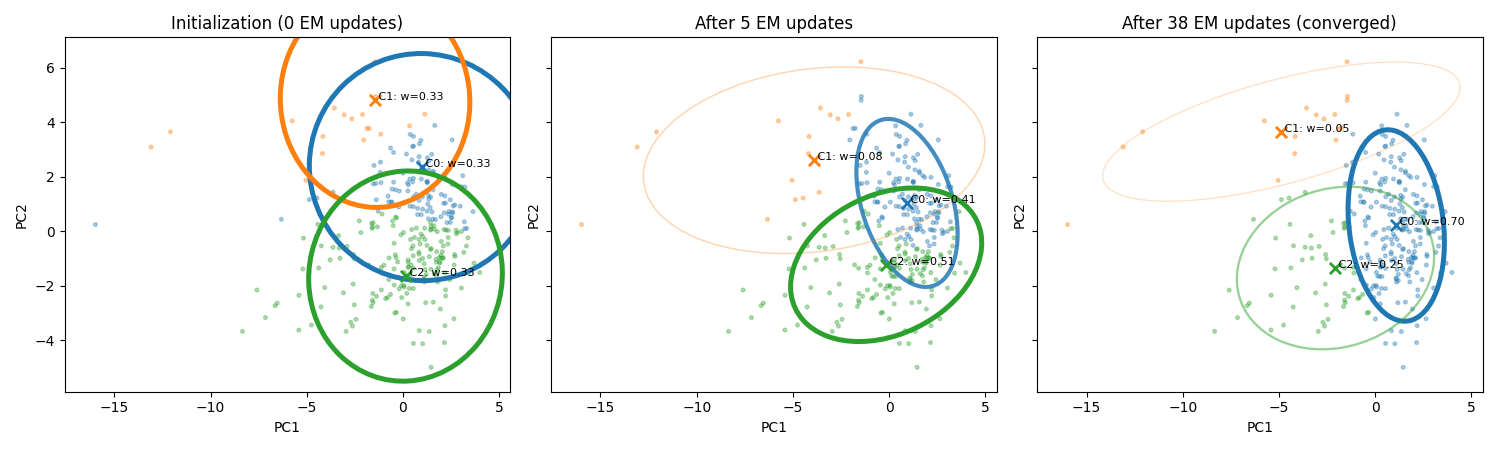

In [7]:
from matplotlib.patches import Ellipse

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
colors = plt.cm.tab10(np.arange(N_CLUSTERS))
for ax, (step, model) in zip(axes, snapshots):
    labels = model.predict(X)
    ax.scatter(X[:, 0], X[:, 1], c=colors[labels], s=7, alpha=.35, rasterized=True)
    for k, (mean, covariance, weight) in enumerate(zip(model.means_, model.covariances_, model.weights_)):
        values, vectors = np.linalg.eigh(covariance)
        order = np.argsort(values)[::-1]
        values, vectors = values[order], vectors[:, order]
        angle = np.degrees(np.arctan2(vectors[1, 0], vectors[0, 0]))
        strength = weight / model.weights_.max()
        ax.add_patch(Ellipse(mean, 4 * np.sqrt(values[0]), 4 * np.sqrt(values[1]), angle=angle,
                             fill=False, edgecolor=colors[k], linewidth=.6 + 3 * strength, alpha=.2 + .8 * strength))
        ax.scatter(*mean, marker="x", s=65, color=colors[k], linewidth=2)
        ax.annotate(f" C{k}: w={weight:.2f}", mean, fontsize=8)
    title = "Initialization (0 EM updates)" if step == 0 else f"After {step} EM updates"
    if step == snapshots[-1][0]: title += " (converged)" if model.converged_ else " (iteration limit)"
    ax.set(title=title, xlabel="PC1", ylabel="PC2")
# Fix one view across snapshots; ellipses can extend outside the observed-data range.
low, high = X.min(axis=0), X.max(axis=0)
pad = np.maximum((high - low) * .08, .1)
axes[0].set(xlim=(low[0]-pad[0], high[0]+pad[0]), ylim=(low[1]-pad[1], high[1]+pad[1]))
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_em_steps.png", dpi=150)
plt.show()
plt.close(fig)

## Return predictions to the image
Maximum posterior probability describes certainty within this fitted model; it is not a validated accuracy estimate. Area fractions count pixels. For superpixels, large superpixels contribute more area; GMM mixture weights instead describe the feature-vector distribution.

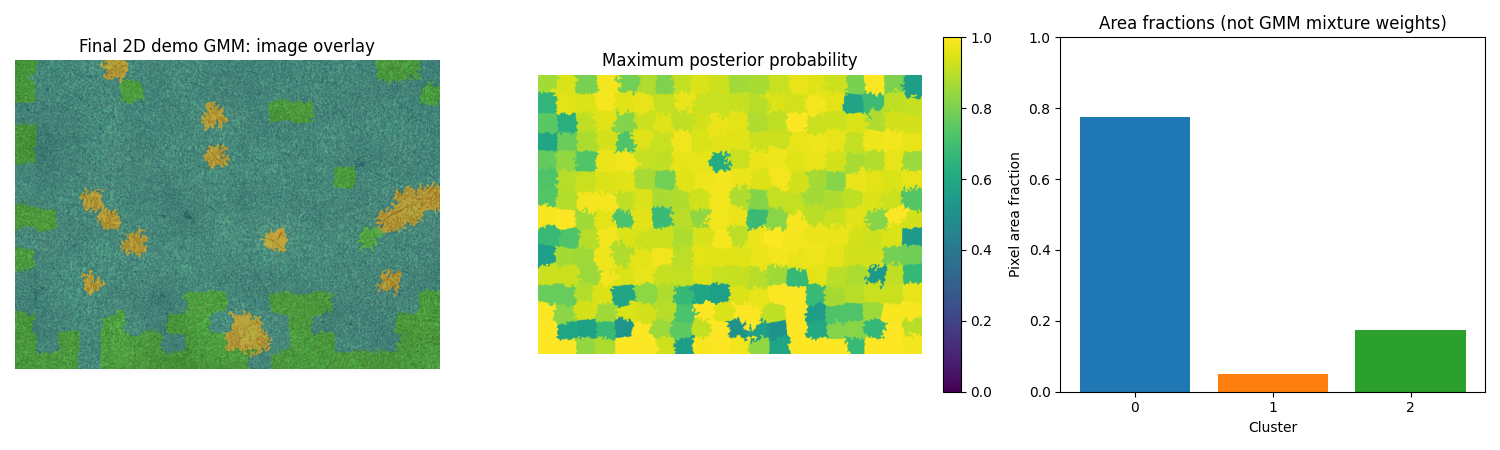

In [8]:
# Convert each superpixel prediction back to the image without relying on consecutive labels.
probabilities = gmm.predict_proba(X)
cluster_ids = probabilities.argmax(axis=1)
confidence = probabilities.max(axis=1)
indices = np.searchsorted(sp_labels, segments)
cluster_map, confidence_map = cluster_ids[indices], confidence[indices]

from matplotlib.colors import ListedColormap

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(image)
axes[0].imshow(cluster_map, cmap=ListedColormap(colors), alpha=.45, vmin=0, vmax=N_CLUSTERS-1)
axes[0].set_title("Final 2D demo GMM: image overlay")
im = axes[1].imshow(confidence_map, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Maximum posterior probability")
fig.colorbar(im, ax=axes[1], fraction=.046)
counts = np.bincount(cluster_map.ravel(), minlength=N_CLUSTERS)
area = counts / counts.sum()
axes[2].bar(np.arange(N_CLUSTERS), area, color=colors)
axes[2].set(xlabel="Cluster", ylabel="Pixel area fraction", xticks=np.arange(N_CLUSTERS), ylim=(0, 1))
axes[2].set_title("Area fractions (not GMM mixture weights)")
for ax in axes[:2]: ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "05_maps_and_areas.png", dpi=120)
plt.show()
plt.close(fig)
np.savez_compressed(OUTPUT_DIR / "demo_maps.npz", cluster_map=cluster_map, confidence_map=confidence_map, area=area)

## Check EM progress
The fitted-sample log likelihood should generally increase as EM updates the parameters. This measures fit to the same image sample, not performance on unseen images.

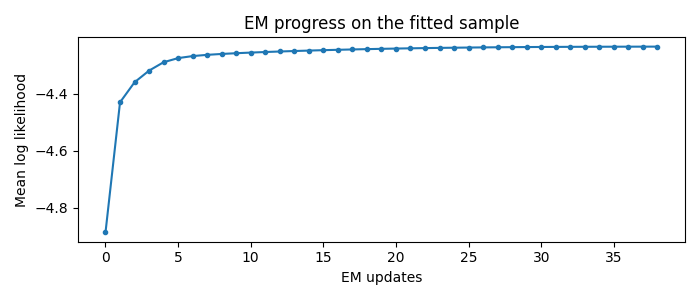

In [9]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(np.arange(len(log_likelihood)), log_likelihood, marker=".")
ax.set(xlabel="EM updates", ylabel="Mean log likelihood", title="EM progress on the fitted sample")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_em_progress.png", dpi=120)
plt.show()
plt.close(fig)

## Prepare labels without inventing ground truth
Inspect the cluster overlay, then enter a manual label in the CSV. Blank labels remain unlabelled. These cluster IDs belong only to this tutorial’s 2D model; do not copy them directly into the main training run. The real workflow then filters confidence, maps labels, splits by source image, trains RF models and evaluates held-out images. One image is insufficient for that evaluation.

In [10]:
rows = []
for k in range(N_CLUSTERS):
    selected = cluster_ids == k
    rows.append({"cluster": k, "n_superpixels": int(selected.sum()), "pixel_area_fraction": area[k],
                 "mean_probability": float(confidence[selected].mean()) if selected.any() else np.nan, "manual_label": ""})
label_path = OUTPUT_DIR / "demo_cluster_labels.csv"
if not label_path.exists(): pd.DataFrame(rows).to_csv(label_path, index=False)
display(pd.read_csv(label_path))
print(f"Edit only manual_label after inspecting the overlay: {label_path}")

,cluster,n_superpixels,pixel_area_fraction,mean_probability,manual_label
0,0,226,0.774034,0.889053,NaN
1,1,17,0.050999,0.827760,NaN
2,2,57,0.174966,0.878128,NaN


Edit only manual_label after inspecting the overlay: /home/kmanabe2403/dune/training/output/tutorial_archived_features_001/demo_cluster_labels.csv


## Try another setting
Change `IMAGE_PATH` or `N_CLUSTERS` and rerun the downstream cells. Choose a new tutorial output directory when comparing settings. Tutorial figures and intermediate arrays are overwritten on rerun; an existing manual-label CSV is preserved, so use a new directory if the image or clustering changes.